In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

import re
import copy

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
train_df = pd.read_csv("/content/drive/My Drive/Book_Genres/bgc_train.csv")
test_df = pd.read_csv("/content/drive/My Drive/Book_Genres/bgc_test.csv")
val_df = pd.read_csv("/content/drive/My Drive/Book_Genres/bgc_dev.csv")

In [4]:
train_df.head()

,Number,Title,Body,Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...


In [5]:
test_df.head()

,Number,Title,Body,Labels
0,1,Teenage Mutant Ninja Turtles: The Box Set Volu...,TMNT co-creator Kevin Eastman and writer Tom W...,Fiction>Graphic Novels & Manga
1,2,Betty & Veronica: Fairy Tales,Take a magical trip down Storybook Lane with t...,Children’s Books>Children’s Middle Grade Books
2,3,Friends & Fauxs,"Tracie Howard is back with all of the Gucci, g...",Fiction>Women’s Fiction
3,4,Anti-Education,"AN NYRB Classics OriginalIn 1869, at the age o...",Nonfiction>Religion & Philosophy>Philosophy
4,5,Fallout,A first-class letter–containing a single sheet...,Fiction>Mystery & Suspense>Espionage Mysteries...


In [6]:
val_df.head()

,Number,Title,Body,Topics
0,1,Trailsman #267: California Casualties,Fargo tangles with a terrible town tyrant!Skye...,Fiction>Western Fiction
1,2,Valentine Be Mine,"Chocolate, flowers, poems, gifts—all of these ...",Children’s Books
2,3,To Mervas,To Mervas is a turbulent journey through the w...,Fiction>Literary Fiction
3,4,Smart Money Moves for African-Americans,The host of PBS’s The Color of Money presents ...,"Nonfiction>Self-Improvement>Personal Growth,No..."
4,5,Another Chance to Get It Right (3rd ed.) (boo...,When Another Chance to Get it Right debuted on...,Nonfiction>Parenting


In [7]:
train_df.shape, test_df.shape, val_df.shape

((58715, 4), (18394, 4), (14785, 4))

In [10]:
train_df.shape[0] + test_df.shape[0] + val_df.shape[0]

91894

In [11]:
train_df.head(10)

,Number,Title,Body,Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...
5,6,Mystery Mother (Replica #8),"Amy knows Nancy isn’t her birth mother, but sh...",Children’s Books>Children’s Middle Grade Books
6,7,The Woman Who Wouldn't Die,The long-awaited follow-up to 2011’s Slash &am...,Fiction>Mystery & Suspense>Crime Mysteries
7,8,The EC Archives: Two-Fisted Tales Volume 3,Before Two-Fisted Tales burst onto the scene i...,Fiction>Graphic Novels & Manga
8,9,The Complete Idiot's Guide to Intermediate Spa...,This revised edition offers expanded coverage ...,"Nonfiction>Reference>Language,Nonfiction>Refer..."
9,10,Comic Sans Murder,"Clare Henry’s snowy Star City, Utah, oasis tur...",Fiction>Mystery & Suspense>Cozy Mysteries


# Top Level Genre Classification :

<hr />

# Data Preprocessing :

In [10]:
test_df = test_df.rename(columns={'Labels' : 'Topics'})

In [11]:
df = pd.concat([train_df, test_df, val_df], ignore_index=True)
df.head()

,Number,Title,Body,Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...


In [12]:
df.isna().sum().sum()

np.int64(0)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Encoded_Topics"] = df["Topics"].str.replace(">", ",").str.split(",")
df.head()

,Number,Title,Body,Topics,Encoded_Topics
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games,"[Nonfiction, Games]"
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga,"[Fiction, Graphic Novels & Manga]"
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books,"[Children’s Books, Children’s Middle Grade Books]"
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction,"[Fiction, Historical Fiction]"
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...,"[Teen & Young Adult, Teen & Young Adult Myster..."


In [15]:
df["Encoded_Topics"].value_counts()

,count
Encoded_Topics,
[Children’s Books],11375
"[Children’s Books, Children’s Middle Grade Books]",5156
"[Fiction, Graphic Novels & Manga]",3793
"[Fiction, Literary Fiction]",3098
"[Nonfiction, Religion & Philosophy, Religion]",2172
...,...
"[Nonfiction, History, World History, European World History, Nonfiction, Travel, Travel: Europe, Nonfiction, Travel, Travel Writing]",1
"[Nonfiction, Self-Improvement, Personal Growth, Nonfiction, Parenting, Nonfiction, Health & Fitness]",1
"[Nonfiction, Parenting, Nonfiction, Arts & Entertainment, Photography]",1


In [16]:
df["Encoded_Topics"].head()

,Encoded_Topics
0,"[Nonfiction, Games]"
1,"[Fiction, Graphic Novels & Manga]"
2,"[Children’s Books, Children’s Middle Grade Books]"
3,"[Fiction, Historical Fiction]"
4,"[Teen & Young Adult, Teen & Young Adult Myster..."


In [17]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

y = mlb.fit_transform(df["Encoded_Topics"])

In [18]:
y.shape

(91894, 147)

In [19]:
y[0]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [20]:
label_counts = pd.Series(
    y.sum(axis=0),
    index=mlb.classes_
).sort_values(ascending=False)

In [21]:
pd.Series(label_counts).describe()

,0
count,147.000000
mean,1896.768707
std,4372.881598
min,5.000000
25%,272.500000
50%,632.000000
75%,1608.500000
max,34270.000000


In [22]:
df["Encoded_Topics"] = list(y)

In [23]:
df["Encoded_Topics"].head()

,Encoded_Topics
0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


# EDA :

In [24]:
df["tokens"] = df["Body"].str.split()
df.head(10)

,Number,Title,Body,Topics,Encoded_Topics,tokens
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Monday’s, Crosswords, Do, with, EaseTuesday’s..."
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Two, of, literary, comics, modern, masters, p..."
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Eleven-year-old, Cornelia, is, the, daughter,..."
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[During, the, English, Age, of, Reason,, a, wo..."
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[A, modern-day, retelling, of, The, Strange, C..."
5,6,Mystery Mother (Replica #8),"Amy knows Nancy isn’t her birth mother, but sh...",Children’s Books>Children’s Middle Grade Books,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Amy, knows, Nancy, isn’t, her, birth, mother,..."
6,7,The Woman Who Wouldn't Die,The long-awaited follow-up to 2011’s Slash &am...,Fiction>Mystery & Suspense>Crime Mysteries,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[The, long-awaited, follow-up, to, 2011’s, Sla..."
7,8,The EC Archives: Two-Fisted Tales Volume 3,Before Two-Fisted Tales burst onto the scene i...,Fiction>Graphic Novels & Manga,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Before, Two-Fisted, Tales, burst, onto, the, ..."
8,9,The Complete Idiot's Guide to Intermediate Spa...,This revised edition offers expanded coverage ...,"Nonfiction>Reference>Language,Nonfiction>Refer...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[This, revised, edition, offers, expanded, cov..."
9,10,Comic Sans Murder,"Clare Henry’s snowy Star City, Utah, oasis tur...",Fiction>Mystery & Suspense>Cozy Mysteries,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Clare, Henry’s, snowy, Star, City,, Utah,, oa..."


In [25]:
df["nbr_tokens"] = df["tokens"].str.len()
df.head()

,Number,Title,Body,Topics,Encoded_Topics,tokens,nbr_tokens
0,1,The New York Times Daily Crossword Puzzles: Th...,Monday’s Crosswords Do with EaseTuesday’s Cros...,Nonfiction>Games,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Monday’s, Crosswords, Do, with, EaseTuesday’s...",127
1,2,Creatures of the Night (Second Edition),Two of literary comics modern masters present ...,Fiction>Graphic Novels & Manga,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Two, of, literary, comics, modern, masters, p...",96
2,3,Cornelia and the Audacious Escapades of the So...,Eleven-year-old Cornelia is the daughter of tw...,Children’s Books>Children’s Middle Grade Books,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[Eleven-year-old, Cornelia, is, the, daughter,...",111
3,4,The Alchemist's Daughter,"During the English Age of Reason, a woman cloi...",Fiction>Historical Fiction,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[During, the, English, Age, of, Reason,, a, wo...",114
4,5,Dangerous Boy,A modern-day retelling of The Strange Case of ...,Teen & Young Adult>Teen & Young Adult Mystery ...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[A, modern-day, retelling, of, The, Strange, C...",148


<Axes: >

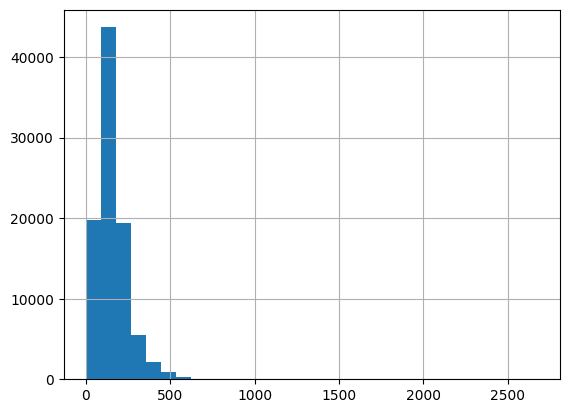

In [26]:
df["nbr_tokens"].hist(bins=30)

In [27]:
df["nbr_tokens"].describe()

,nbr_tokens
count,91894.000000
mean,156.962479
std,89.621293
min,1.000000
25%,97.000000
50%,142.000000
75%,195.000000
max,2675.000000


In [28]:
print("mean", df["nbr_tokens"].mean())
print("median", df["nbr_tokens"].median())

mean 156.962478507846
median 142.0


In [29]:
df[df["nbr_tokens"] > 500].shape[0]

657

# Data Splitting :

In [30]:
# train_df, test_df, val_df

### Tokenization :

In [31]:
train_df["tokens"] = train_df["Body"].str.split()
test_df["tokens"] = test_df["Body"].str.split()
val_df["tokens"] = val_df["Body"].str.split()

### Extracting top level topic :

In [32]:
train_df["Encoded_Topics"] = train_df["Topics"].str.replace(">", ",").str.split(",")
test_df["Encoded_Topics"] = test_df["Topics"].str.replace(">", ",").str.split(",")
val_df["Encoded_Topics"] = val_df["Topics"].str.replace(">", ",").str.split(",")

### Label encoding :

In [33]:
y_train = mlb.fit_transform(train_df["Encoded_Topics"])
y_test = mlb.transform(test_df["Encoded_Topics"])
y_val = mlb.transform(val_df["Encoded_Topics"])

In [34]:
labels = mlb.classes_
labels[:10]

array([' Home & Garden', '1950 – Present Military History',
       '19th Century U.S. History', '20th Century U.S. History',
       '21st Century U.S. History', 'African World History',
       'Alternative Therapies', 'Ancient World History', 'Art',
       'Arts & Entertainment'], dtype=object)

In [35]:
train_df["Encoded_Topics"] = list(y_train)
test_df["Encoded_Topics"] = list(y_test)
val_df["Encoded_Topics"] = list(y_val)

### Vocab (Word_idx) :
- **vocabulary** is created using only **training data** !

In [36]:
from collections import Counter

word_counts = Counter()

for tokens in train_df["tokens"]:
	word_counts.update(tokens)

In [37]:
most_common_words = word_counts.most_common(50_000)
len(most_common_words)

50000

In [38]:
most_common_words[:5]

[('the', 473099),
 ('and', 346644),
 ('of', 314815),
 ('a', 233916),
 ('to', 232819)]

In [39]:
# all_tokens = [
#   token for tokens in train_df["tokens"]
#   for token in tokens
# ]

# print(len(all_tokens))

# all_tokens = list(dict.fromkeys(all_tokens))

# print(len(all_tokens))

all_tokens = [
  token for (token, frq) in most_common_words
]

print(len(all_tokens))

50000


In [40]:
word_idx = {
  "<PAD>" : 0,
  "<UNK>" : 1
}

for token in all_tokens:
  word_idx[token] = len(word_idx)

for key, value in list(word_idx.items())[:5]:
    print(f"{key} : {value}")

<PAD> : 0
<UNK> : 1
the : 2
and : 3
of : 4


### Encoding :

In [41]:
train_df["encoded_tokens"] = train_df["tokens"].apply(
  lambda tokens : [word_idx.get(token, word_idx["<UNK>"]) for token in tokens]
)
test_df["encoded_tokens"] = test_df["tokens"].apply(
  lambda tokens : [word_idx.get(token, word_idx["<UNK>"]) for token in tokens]
)
val_df["encoded_tokens"] = val_df["tokens"].apply(
  lambda tokens : [word_idx.get(token, word_idx["<UNK>"]) for token in tokens]
)

In [42]:
train_df["encoded_tokens"].head()

,encoded_tokens
0,"[1, 39871, 1242, 10, 1, 39871, 674, 5, 1, 3987..."
1,"[1207, 4, 386, 1830, 227, 2638, 698, 5, 1731, ..."
2,"[22167, 28229, 8, 2, 570, 4, 86, 6685, 1, 1775..."
3,"[2639, 2, 499, 2239, 4, 44968, 5, 150, 18059, ..."
4,"[52, 2999, 3884, 4, 16, 7465, 8775, 4, 281, 29..."


### Padding :

In [43]:
max_len = 500

def collate_fn_cnn(batch):
	body, topic = zip(*batch)

	body = [torch.tensor(b, dtype=torch.long) for b in body]

	topic = torch.tensor(topic, dtype=torch.float32)

	body = [b[:max_len] for b in body]

	body = pad_sequence(
		body,
		padding_value = word_idx["<PAD>"],
		batch_first = True
	)

	return body, topic

# BGC Class :

In [44]:
class BGCDataset(Dataset):
	def __init__(self, body, topic):
		super().__init__()
		self.body = body
		self.topic = topic

	def __len__(self):
		return self.body.shape[0]

	def __getitem__(self, idx):
		return self.body.iloc[idx], self.topic.iloc[idx]

### Dataset & Dataloader :

In [45]:
train_data = BGCDataset(train_df["encoded_tokens"], train_df["Encoded_Topics"])
val_data = BGCDataset(val_df["encoded_tokens"], val_df["Encoded_Topics"])
test_data = BGCDataset(test_df["encoded_tokens"], test_df["Encoded_Topics"])

train_loader_cnn = DataLoader(train_data, batch_size=128, shuffle=True, collate_fn=collate_fn_cnn)
val_loader_cnn = DataLoader(val_data, batch_size=128, shuffle=True, collate_fn=collate_fn_cnn)
test_loader_cnn = DataLoader(test_data, batch_size=128, shuffle=True, collate_fn=collate_fn_cnn)

# CNN Model :

In [46]:
class CnnModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, num_classes):
		super().__init__()
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])

		self.conv2 = nn.Conv1d(embedding_dim, embedding_dim, kernel_size=2, stride=1, padding=1)
		self.conv3 = nn.Conv1d(embedding_dim, embedding_dim, kernel_size=3, stride=1, padding=1)
		self.conv4 = nn.Conv1d(embedding_dim, embedding_dim, kernel_size=4, stride=1, padding=2)

		self.dropout = nn.Dropout(0.3)

		self.fc = nn.Linear(embedding_dim * 3, num_classes)

	def forward(self, x):  # (batch_size, sequence_length)
		x = self.embedding(x) # (batch_size, sequence_length, embedding_dim)
		x = x.permute(0, 2, 1) # (batch_size, embedding_dim, sequence_length)
		
		x2 = F.relu(self.conv2(x))
		x3 = F.relu(self.conv3(x))
		x4 = F.relu(self.conv4(x))

		p2 = F.max_pool1d(x2, x2.shape[2]).squeeze(2) # (batch_size, embedding_dim)
		p3 = F.max_pool1d(x3, x3.shape[2]).squeeze(2) # (batch_size, embedding_dim)
		p4 = F.max_pool1d(x4, x4.shape[2]).squeeze(2) # (batch_size, embedding_dim)

		x = torch.cat([p2, p3, p4], dim=1)
		x = self.dropout(x)
		out = self.fc(x)
		return out

### training :

In [47]:
device = torch.device("cuda")

In [49]:
labels[:5]

array([' Home & Garden', '1950 – Present Military History',
       '19th Century U.S. History', '20th Century U.S. History',
       '21st Century U.S. History'], dtype=object)

In [50]:
vocab_size = len(word_idx)
embedding_dim = 100
num_classes = len(labels)

In [51]:
positive = train_df["Encoded_Topics"].sum(axis=0)
negative = len(train_df["Encoded_Topics"]) - positive

pos_weight = np.sqrt(negative / positive)

pos_weight = torch.tensor(pos_weight, dtype=torch.float32,
  device=device
)

In [53]:
cnn_model = CnnModel(vocab_size, embedding_dim, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  cnn_model.parameters(),
	lr=0.001,
	weight_decay=1e-4
)

In [54]:
num_epochs = 30
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	cnn_model.train()

	for body, topic in train_loader_cnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = cnn_model(body)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_cnn)
	# validation :
	val_loss = 0.0
	cnn_model.eval()

	with torch.no_grad():
		for body, topic in val_loader_cnn:
			body = body.to(device)
			topic = topic.to(device)

			output = cnn_model(body)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_cnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(cnn_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

/tmp/ipykernel_1670/2070454190.py:8: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  topic = torch.tensor(topic, dtype=torch.float32)


epoch : 0 train_loss : 0.3099 val_loss : 0.2635
best loss saved
epoch : 1 train_loss : 0.2562 val_loss : 0.2374
best loss saved
epoch : 2 train_loss : 0.2357 val_loss : 0.2241
best loss saved
epoch : 3 train_loss : 0.2230 val_loss : 0.2154
best loss saved
epoch : 4 train_loss : 0.2140 val_loss : 0.2070
best loss saved
epoch : 5 train_loss : 0.2069 val_loss : 0.2016
best loss saved
epoch : 6 train_loss : 0.2014 val_loss : 0.1964
best loss saved
epoch : 7 train_loss : 0.1964 val_loss : 0.1919
best loss saved
epoch : 8 train_loss : 0.1919 val_loss : 0.1878
best loss saved
epoch : 9 train_loss : 0.1875 val_loss : 0.1833
best loss saved
epoch : 10 train_loss : 0.1835 val_loss : 0.1791
best loss saved
epoch : 11 train_loss : 0.1796 val_loss : 0.1754
best loss saved
epoch : 12 train_loss : 0.1763 val_loss : 0.1719
best loss saved
epoch : 13 train_loss : 0.1736 val_loss : 0.1708
best loss saved
epoch : 14 train_loss : 0.1715 val_loss : 0.1686
best loss saved
epoch : 15 train_loss : 0.1696 val_

In [55]:
cnn_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [91]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

cnn_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic in test_loader_cnn:
		body = body.to(device)
		topic = topic.to(device)

		output = cnn_model(body)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_cnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm[:10]}")

print("labels : ", labels[:10])

loss : 0.1589 accuracy : 0.9804
f1_macro : 0.3423 f1_micro : 0.5767 f1_weighted : 0.5894
confusion matrix : 
tensor([[[17913,   212],
         [   82,   187]],

        [[18265,    73],
         [   41,    15]],

        [[18355,     9],
         [   30,     0]],

        [[18140,   155],
         [   75,    24]],

        [[18347,    21],
         [   25,     1]],

        [[18377,     6],
         [   11,     0]],

        [[17861,   320],
         [   78,   135]],

        [[18339,    29],
         [   12,    14]],

        [[17802,   285],
         [  123,   184]],

        [[17239,   430],
         [  294,   431]]], device='cuda:0')
labels :  [' Home & Garden' '1950 – Present Military History'
 '19th Century U.S. History' '20th Century U.S. History'
 '21st Century U.S. History' 'African World History'
 'Alternative Therapies' 'Ancient World History' 'Art'
 'Arts & Entertainment']


# RNN Model :

### Padding : 

In [60]:
def collate_fn_rnn(batch):
	body, topic = zip(*batch)

	body = [
		torch.tensor(b, dtype=torch.long) for b in body
	]
	topic = torch.tensor(topic, dtype=torch.float32)
	lengths = torch.tensor(
		[len(b) for b in body],
		dtype=torch.long
	)

	body = pad_sequence(
		body,
		batch_first = True,
		padding_value = word_idx["<PAD>"]
	)

	return body, topic, lengths

In [61]:
train_loader_rnn = DataLoader(train_data, batch_size=128, shuffle=True, collate_fn=collate_fn_rnn)
val_loader_rnn = DataLoader(val_data, batch_size=128, shuffle=True, collate_fn=collate_fn_rnn)
test_loader_rnn = DataLoader(test_data, batch_size=128, shuffle=True, collate_fn=collate_fn_rnn)

### Model :

In [62]:
class RNNModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, num_classes):
		super().__init__()
		self.hidden_size = hidden_size
		self.num_layers = num_layers
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])
		self.rnn = nn.RNN(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
		self.dropout = nn.Dropout(0.3)
		self.fc = nn.Linear(hidden_size, num_classes)

	def forward(self, x, lengths):
		x = self.embedding(x)

		packed = pack_padded_sequence(
			x,
			lengths.cpu(),
			batch_first=True,
			enforce_sorted=False
		)

		h0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		_, hn = self.rnn(packed, h0)
		hn = hn[-1]
		hn = self.dropout(hn)
		out = self.fc(hn)
		return out

### Training :

In [63]:
# vocab_size
# embedding_dim
# num_classes
num_layers = 1
hidden_size = 128

In [64]:
rnn_model = RNNModel(vocab_size, embedding_dim, hidden_size, num_layers, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  rnn_model.parameters(),
  lr=0.001,
  weight_decay=1e-4
)

In [65]:
num_epochs = 20
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	rnn_model.train()

	for body, topic, lengths in train_loader_rnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = rnn_model(body, lengths)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_rnn)
	# validation :
	val_loss = 0.0
	rnn_model.eval()

	with torch.no_grad():
		for body, topic, lengths in val_loader_rnn:
			body = body.to(device)
			topic = topic.to(device)

			output = rnn_model(body, lengths)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_rnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(rnn_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

epoch : 0 train_loss : 0.3427 val_loss : 0.3192
best loss saved
epoch : 1 train_loss : 0.3173 val_loss : 0.3199
epoch : 2 train_loss : 0.3154 val_loss : 0.3105
best loss saved
epoch : 3 train_loss : 0.3138 val_loss : 0.3156
epoch : 4 train_loss : 0.3127 val_loss : 0.3107
epoch : 5 train_loss : 0.3106 val_loss : 0.3080
best loss saved
epoch : 6 train_loss : 0.3090 val_loss : 0.3115
epoch : 7 train_loss : 0.3087 val_loss : 0.3060
best loss saved
epoch : 8 train_loss : 0.3024 val_loss : 0.2986
best loss saved
epoch : 9 train_loss : 0.3062 val_loss : 0.3050
epoch : 10 train_loss : 0.3062 val_loss : 0.3061
epoch : 11 train_loss : 0.3019 val_loss : 0.3062
epoch : 12 train_loss : 0.2991 val_loss : 0.3000
epoch : 13 train_loss : 0.3000 val_loss : 0.3050
epoch : 14 train_loss : 0.3000 val_loss : 0.3006
epoch : 15 train_loss : 0.2950 val_loss : 0.2993
epoch : 16 train_loss : 0.2913 val_loss : 0.2937
best loss saved
epoch : 17 train_loss : 0.2872 val_loss : 0.2896
best loss saved
epoch : 18 train

In [66]:
rnn_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [90]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

rnn_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic, lengths in test_loader_rnn:
		body = body.to(device)
		topic = topic.to(device)

		output = rnn_model(body, lengths)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_rnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm[:10]}")

print("labels : ", labels[:10])

loss : 0.2872 accuracy : 0.9784
f1_macro : 0.0519 f1_micro : 0.2845 f1_weighted : 0.2078
confusion matrix : 
tensor([[[18090,    35],
         [  266,     3]],

        [[18338,     0],
         [   56,     0]],

        [[18364,     0],
         [   30,     0]],

        [[18295,     0],
         [   99,     0]],

        [[18368,     0],
         [   26,     0]],

        [[18383,     0],
         [   11,     0]],

        [[18179,     2],
         [  213,     0]],

        [[18368,     0],
         [   26,     0]],

        [[18087,     0],
         [  307,     0]],

        [[17641,    28],
         [  725,     0]]], device='cuda:0')
labels :  [' Home & Garden' '1950 – Present Military History'
 '19th Century U.S. History' '20th Century U.S. History'
 '21st Century U.S. History' 'African World History'
 'Alternative Therapies' 'Ancient World History' 'Art'
 'Arts & Entertainment']


# LSTM Model :

In [68]:
class LSTMModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, num_classes):
		super().__init__()
		self.hidden_size = hidden_size
		self.num_layers = num_layers
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])
		self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
		self.dropout = nn.Dropout(0.3)
		self.fc = nn.Linear(hidden_size, num_classes)

	def forward(self, x, lengths):
		x = self.embedding(x)

		packed = pack_padded_sequence(
			x,
			lengths.cpu(),
			batch_first=True,
			enforce_sorted=False
		)

		h0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		c0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		_, (hn, cn) = self.lstm(packed, (h0, c0))
		hn = hn[-1]
		hn = self.dropout(hn)
		out = self.fc(hn)
		return out

### Training :

In [73]:
lstm_model = LSTMModel(vocab_size, embedding_dim, hidden_size, num_layers, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  lstm_model.parameters(),
  lr=0.001,
  weight_decay=1e-4
)

In [74]:
num_epochs = 30
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	lstm_model.train()

	for body, topic, lengths in train_loader_rnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = lstm_model(body, lengths)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_rnn)
	# validation :
	val_loss = 0.0
	lstm_model.eval()

	with torch.no_grad():
		for body, topic, lengths in val_loader_rnn:
			body = body.to(device)
			topic = topic.to(device)

			output = lstm_model(body, lengths)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_rnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(lstm_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

epoch : 0 train_loss : 0.3403 val_loss : 0.3203
best loss saved
epoch : 1 train_loss : 0.2987 val_loss : 0.2787
best loss saved
epoch : 2 train_loss : 0.2682 val_loss : 0.2522
best loss saved
epoch : 3 train_loss : 0.2501 val_loss : 0.2436
best loss saved
epoch : 4 train_loss : 0.2364 val_loss : 0.2269
best loss saved
epoch : 5 train_loss : 0.2237 val_loss : 0.2134
best loss saved
epoch : 6 train_loss : 0.2112 val_loss : 0.2048
best loss saved
epoch : 7 train_loss : 0.2013 val_loss : 0.1973
best loss saved
epoch : 8 train_loss : 0.1933 val_loss : 0.1896
best loss saved
epoch : 9 train_loss : 0.1867 val_loss : 0.1886
best loss saved
epoch : 10 train_loss : 0.1820 val_loss : 0.1899
epoch : 11 train_loss : 0.1778 val_loss : 0.1828
best loss saved
epoch : 12 train_loss : 0.1744 val_loss : 0.1792
best loss saved
epoch : 13 train_loss : 0.1702 val_loss : 0.1764
best loss saved
epoch : 14 train_loss : 0.1676 val_loss : 0.1749
best loss saved
epoch : 15 train_loss : 0.1641 val_loss : 0.1823
ep

In [75]:
lstm_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [89]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

lstm_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic, lengths in test_loader_rnn:
		body = body.to(device)
		topic = topic.to(device)

		output = lstm_model(body, lengths)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_rnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm[:10]}")

print("labels : ", labels[:10])

loss : 0.1644 accuracy : 0.9703
f1_macro : 0.2658 f1_micro : 0.4906 f1_weighted : 0.5604
confusion matrix : 
tensor([[[17779,   346],
         [   69,   200]],

        [[17842,   496],
         [   10,    46]],

        [[17854,   510],
         [   18,    12]],

        [[17389,   906],
         [   47,    52]],

        [[18181,   187],
         [   22,     4]],

        [[18366,    17],
         [   11,     0]],

        [[17870,   311],
         [   66,   147]],

        [[18301,    67],
         [   19,     7]],

        [[17650,   437],
         [  111,   196]],

        [[17039,   630],
         [  260,   465]]], device='cuda:0')
labels :  [' Home & Garden' '1950 – Present Military History'
 '19th Century U.S. History' '20th Century U.S. History'
 '21st Century U.S. History' 'African World History'
 'Alternative Therapies' 'Ancient World History' 'Art'
 'Arts & Entertainment']


# GRU Model :

In [77]:
class GRUModel(nn.Module):
	def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, num_classes):
		super().__init__()
		self.hidden_size = hidden_size
		self.num_layers = num_layers
		self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=word_idx["<PAD>"])
		self.gru = nn.GRU(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
		self.dropout = nn.Dropout(0.3)
		self.fc = nn.Linear(hidden_size, num_classes)

	def forward(self, x, lengths):
		x = self.embedding(x)

		packed = pack_padded_sequence(
			x,
			lengths.cpu(),
			batch_first=True,
			enforce_sorted=False
		)

		h0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_size, device=device)
		_, hn = self.gru(packed, h0)
		hn = hn[-1]
		hn = self.dropout(hn)
		out = self.fc(hn)
		return out

### Training :

In [82]:
num_layers = 1
hidden_size = 128

In [83]:
gru_model = GRUModel(vocab_size, embedding_dim, hidden_size, num_layers, num_classes).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(
  gru_model.parameters(),
  lr=0.001,
  weight_decay=1e-4
)

In [84]:
num_epochs = 30
best_state_dict = None
best_loss = float("inf")

for epoch in range(num_epochs):

	# training :
	train_loss = 0.0
	gru_model.train()

	for body, topic, lengths in train_loader_rnn:
		optimizer.zero_grad()

		body = body.to(device)
		topic = topic.to(device)

		output = gru_model(body, lengths)
		loss = criterion(output, topic)
		train_loss += loss.item()

		loss.backward()
		optimizer.step()

	train_loss /= len(train_loader_rnn)
	# validation :
	val_loss = 0.0
	gru_model.eval()

	with torch.no_grad():
		for body, topic, lengths in val_loader_rnn:
			body = body.to(device)
			topic = topic.to(device)

			output = gru_model(body, lengths)
			loss = criterion(output, topic)
			val_loss += loss.item()

	val_loss /= len(val_loader_rnn)

	print(f"epoch : {epoch} train_loss : {train_loss:.4f} val_loss : {val_loss:.4f}")

	if(val_loss < best_loss):
		best_state_dict = copy.deepcopy(gru_model.state_dict())
		best_loss = val_loss
		print("best loss saved")

epoch : 0 train_loss : 0.3385 val_loss : 0.3165
best loss saved
epoch : 1 train_loss : 0.2944 val_loss : 0.2718
best loss saved
epoch : 2 train_loss : 0.2630 val_loss : 0.2579
best loss saved
epoch : 3 train_loss : 0.2481 val_loss : 0.2388
best loss saved
epoch : 4 train_loss : 0.2363 val_loss : 0.2299
best loss saved
epoch : 5 train_loss : 0.2260 val_loss : 0.2236
best loss saved
epoch : 6 train_loss : 0.2168 val_loss : 0.2102
best loss saved
epoch : 7 train_loss : 0.2096 val_loss : 0.2066
best loss saved
epoch : 8 train_loss : 0.2029 val_loss : 0.2000
best loss saved
epoch : 9 train_loss : 0.1969 val_loss : 0.2004
epoch : 10 train_loss : 0.1923 val_loss : 0.1907
best loss saved
epoch : 11 train_loss : 0.1874 val_loss : 0.1932
epoch : 12 train_loss : 0.1843 val_loss : 0.1901
best loss saved
epoch : 13 train_loss : 0.1793 val_loss : 0.1853
best loss saved
epoch : 14 train_loss : 0.1765 val_loss : 0.1856
epoch : 15 train_loss : 0.1725 val_loss : 0.1847
best loss saved
epoch : 16 train_l

In [85]:
gru_model.load_state_dict(best_state_dict)

<All keys matched successfully>

### Evaluation :

In [88]:
from torchmetrics.classification import MultilabelAccuracy, MultilabelConfusionMatrix, MultilabelF1Score

accuracy = MultilabelAccuracy(num_classes).to(device)
cm = MultilabelConfusionMatrix(num_classes).to(device)
f1_micro = MultilabelF1Score(num_classes, average='micro').to(device)
f1_macro = MultilabelF1Score(num_classes, average='macro').to(device)
f1_weighted = MultilabelF1Score(num_classes, average='weighted').to(device)

gru_model.eval()
test_loss = 0.0

with torch.no_grad():
	for body, topic, lengths in test_loader_rnn:
		body = body.to(device)
		topic = topic.to(device)

		output = gru_model(body, lengths)
		loss = criterion(output, topic)
		test_loss += loss.item()

		accuracy.update(output, topic)
		cm.update(output, topic.int())
		f1_micro.update(output, topic)
		f1_macro.update(output, topic)
		f1_weighted.update(output, topic)

test_loss /= len(test_loader_rnn)
accuracy = accuracy.compute()
cm = cm.compute()
f1_micro = f1_micro.compute()
f1_macro = f1_macro.compute()
f1_weighted = f1_weighted.compute()

print(f"loss : {test_loss:.4f} accuracy : {accuracy:.4f}")
print(f"f1_macro : {f1_macro:.4f} f1_micro : {f1_micro:.4f} f1_weighted : {f1_weighted:.4f}")
print(f"confusion matrix : \n{cm[:10]}")

print("labels : ", labels[:10])

loss : 0.1693 accuracy : 0.9716
f1_macro : 0.2613 f1_micro : 0.4998 f1_weighted : 0.5492
confusion matrix : 
tensor([[[17640,   485],
         [   66,   203]],

        [[18136,   202],
         [   31,    25]],

        [[18115,   249],
         [   23,     7]],

        [[18013,   282],
         [   74,    25]],

        [[18314,    54],
         [   21,     5]],

        [[18383,     0],
         [   11,     0]],

        [[17572,   609],
         [   51,   162]],

        [[18252,   116],
         [   20,     6]],

        [[17260,   827],
         [  105,   202]],

        [[16590,  1079],
         [  252,   473]]], device='cuda:0')
labels :  [' Home & Garden' '1950 – Present Military History'
 '19th Century U.S. History' '20th Century U.S. History'
 '21st Century U.S. History' 'African World History'
 'Alternative Therapies' 'Ancient World History' 'Art'
 'Arts & Entertainment']
